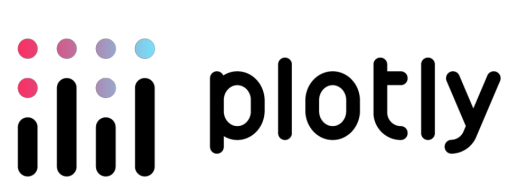

# What is Plotly ?

- A JavaScript graphing library
- Plotly has a Python wrapper
- JavaScript knowledge not needed
---

# Why Plotly?

**Plotly has a number of unique advantages:**

- Fast and easy to use
- Low code/low effort options using plotly.express
- Customizable
- Interactivity
---

# The Plotly documentation

Plotly has very nice and interactive documentation page:

1. [Interactive documentation](https://plotly.com/python/)

2. Very detailed reference page for [specific plots](https://plotly.com/python/reference/index/)

---

# Strengths & drawbacks

We chose **Plotly** because it is **interactive and easy to use**.

**Strengths**

- Interactive by default:
- Short code:
- No web design:
- Easy to share:
- Works in Google Colab, Jupyter and VS Code

**Drawbacks**

- Interactive is not always better. printed report or a PDF.
- Filters need Python running. A saved HTML page keeps hover and zoom, but it cannot filter the data by itself. Real web apps need an extra tool such as **Dash**.
- Dropdown widgets are fragile in Google Colab.
- Combining charts on one page is fiddly.
- Fewer ready-made dashboard features: than BI tools such as Power BI or Tableau.
---

# Why Plotly is still worth learning

Despite these, **Plotly is one of the most popular and recommended choices for building interactive charts**, especially for **beginners and intermediate learners**.

**Why it matters**

- Low barrier to entry:

- Room to grow:

- Works with pandas:

- Wide range of chart types:

- A path to dashboards:

- Open source and free:

- Transferable skills: Power BI and Tableau


**Bottom line:** every tool has trade-offs. Plotly's strengths for exploring and presenting data outweigh its drawbacks at this level, which makes it a strong foundation for learning data visualization.

#A Sales Analysis Dashboard with **Plotly** (Python)


---

**The main question of this dashboard**

**Where does our revenue come from, where are we losing profit and customers, and what should we change?**

A good dashboard is not a pile of charts. It is a **story**, and every story rests on three pillars:

- **Data:** a clean, trusted dataset (we load, explore, clean and prepare it)
- **Narrative:** one question per chart, and one sentence that says what the chart tells us
- **Visuals:** interactive Plotly charts that answer each question, then combine into one dashboard

---

# Where Do We Make Money, and Where Do We Lose It?


## The storyline: five acts

Each act answers one big question with one or more charts.

**Act 1 · The big picture:** How is the business doing at a glance?

**Act 2 · Where does the money come from?** Which category earns the most revenue? Is it also the most profitable? Which regions drive revenue, and which region-category pairs are strongest?

**Act 3 · How is it changing?** How does revenue evolve, and who drives the growth?

**Act 4 · What is hurting us?** Do bigger discounts hurt the profit margin? Where do we lose the most customers?

**Act 5 · Who delivers?** Who are our top 10 performers?

Finally we **assemble the dashboard**, and write the **conclusion** of our story.

# Agenda

In this notebook we go from single charts to a full interactive dashboard in four steps.

**1. Build individual plots**
Create each chart on its own with `plotly.express` (scatter, bar, treemap, and more).

**2. Combine them into a dashboard**
Bring the individual charts together on one page using `make_subplots`, with a shared layout.

**3. Clean and improve the dashboard with Gen AI**
Use a Gen AI assistant to tidy the code, fix layout and legend issues, improve colours and titles for better storytelling.

**4. Build the final version with Dash**
Rebuild the dashboard as a web app with the **Dash** library, so filters and dropdowns work properly and the result can be shared.

---

## Setup

Run the next cell once. On Google Colab, Plotly is already installed.

In [ ]:
# ── Setup · Import the libraries ──────────────────────────────────────────
import os                                       # check if the sample CSV exists
import itertools                                # cycle through the colour palette
import pandas as pd                             # tables
import numpy as np                              # numbers
import plotly.express as px                     # one-line charts
import plotly.graph_objects as go               # charts built from traces
import plotly.io as pio                         # chart themes
from plotly.subplots import make_subplots       # many charts on one page
from IPython.display import Markdown, display   # formatted text from code

pio.templates.default = 'plotly_white'          # clean look for every chart

---

# Pillar 1 · Data

A story is only as good as its data. In four short steps we **load**, **explore**, **clean** and **prepare** the dataset.

### Step 1 · Load the data

**Question:** Can we read the sales file into Python?

- The file is `tech_sales_data.csv`. In Colab, upload it in the **Files** panel on the left (or mount Google Drive).
- **No file yet?** The next cell creates a sample file with the same columns, so you can run the whole notebook right away.
- `pd.read_csv()` reads the file into a table called `df`.

In [ ]:
#@title Create a sample dataset (skipped automatically if tech_sales_data.csv already exists)
if not os.path.exists('tech_sales_data.csv'):
    rng, n = np.random.default_rng(42), 6000
    geo = {'North America': ['USA', 'Canada'], 'Europe': ['France', 'Germany', 'UK'],
           'Asia Pacific': ['Japan', 'India', 'Australia'], 'Latin America': ['Brazil', 'Mexico']}
    prod = {'Hardware': ['Laptop', 'Server', 'Router'], 'Software': ['CRM Suite', 'Analytics Pro'],
            'Cloud Services': ['Cloud Storage', 'Cloud Compute'],
            'Consulting': ['Strategy Project', 'Migration Project'], 'Support': ['Support Plan']}
    size = {'Hardware': 1.0, 'Software': 0.8, 'Cloud Services': 1.1, 'Consulting': 1.8, 'Support': 0.4}

    days = pd.date_range('2022-01-01', '2025-12-31')
    w = (1 + 0.25 * (days.year.to_numpy() - 2022)) * np.where(days.month.to_numpy() >= 10, 1.4, 1.0)
    region = rng.choice(list(geo), n, p=[0.35, 0.30, 0.25, 0.10])
    category = rng.choice(list(prod), n, p=[0.28, 0.24, 0.20, 0.12, 0.16])
    discount = rng.choice([0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30], n,
                          p=[0.30, 0.20, 0.18, 0.12, 0.10, 0.06, 0.04])

    pd.DataFrame({
        'Order_Date': rng.choice(days, n, p=w / w.sum()),
        'Region': region,
        'Country': [rng.choice(geo[r]) for r in region],
        'Category': category,
        'Product': [rng.choice(prod[c]) for c in category],
        'Salesperson': rng.choice(['Alice Martin', 'Ben Carter', 'Chloe Dubois', 'Daniel Kim', 'Emma Rossi',
                                   'Farid Haddad', 'Grace Lee', 'Hugo Moreau', 'Isabel Silva', 'Jack Brown',
                                   'Lena Fischer', 'Mateo Garcia'], n),
        'Units_Sold': rng.integers(1, 60, n),
        'Discount': discount,
        'Sales_Revenue': (pd.Series(category).map(size).values * rng.lognormal(8.0, 0.8, n)).round(2),
        'Profit_Margin': np.clip(0.30 - 0.55 * discount + rng.normal(0, 0.05, n), -0.2, 0.6).round(3),
        'Customer_Satisfaction': np.clip(rng.normal(4.1, 0.5, n), 1, 5).round(2),
        'Churn_Flag': (rng.random(n) < 0.10 + 0.25 * discount).astype(int),
    }).to_csv('tech_sales_data.csv', index=False)
    print('Sample file created: tech_sales_data.csv')

Sample file created: tech_sales_data.csv


In [ ]:
# ── Step 1 · Load the data ────────────────────────────────────────────────
df = pd.read_csv('tech_sales_data.csv')

### Step 2 · Explore the data

We use a few simple pandas functions to inspect the table before drawing anything.

**2a · What does the data look like?**

- `df.shape` gives `(rows, columns)`
- `df.head()` shows the first rows, so we see what **one row** represents (here: one sales order)

In [ ]:
# Step 2a · Size and sample rows
df.head()

,Order_Date,Region,Country,Category,Product,Salesperson,Units_Sold,Discount,Sales_Revenue,Profit_Margin,Customer_Satisfaction,Churn_Flag
0,2022-10-21,Asia Pacific,Japan,Software,Analytics Pro,Lena Fischer,35,0.10,2340.72,0.198,4.94,1
1,2025-05-29,Europe,UK,Hardware,Server,Farid Haddad,19,0.05,3176.60,0.271,3.49,1
2,2025-12-21,Asia Pacific,Japan,Cloud Services,Cloud Storage,Ben Carter,9,0.00,5959.81,0.266,4.50,0
3,2023-10-31,Asia Pacific,India,Hardware,Server,Hugo Moreau,31,0.30,3526.74,0.035,3.72,0
4,2025-08-20,North America,Canada,Hardware,Laptop,Farid Haddad,19,0.00,8944.69,0.351,5.00,0


**2b · What type is each column, and what are typical values?**

- `df.info()` lists the columns, their data types and how many values are filled
- `df.describe()` gives the minimum, average and maximum of every numeric column

In [ ]:
# Step 2b · Types and summary statistics
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Order_Date             6000 non-null   object 
 1   Region                 6000 non-null   object 
 2   Country                6000 non-null   object 
 3   Category               6000 non-null   object 
 4   Product                6000 non-null   object 
 5   Salesperson            6000 non-null   object 
 6   Units_Sold             6000 non-null   int64  
 7   Discount               6000 non-null   float64
 8   Sales_Revenue          6000 non-null   float64
 9   Profit_Margin          6000 non-null   float64
 10  Customer_Satisfaction  6000 non-null   float64
 11  Churn_Flag             6000 non-null   int64  
dtypes: float64(4), int64(2), object(6)
memory usage: 562.6+ KB


In [ ]:
df.describe().round(2)

,Units_Sold,Discount,Sales_Revenue,Profit_Margin,Customer_Satisfaction,Churn_Flag
count,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00
mean,29.67,0.09,3949.48,0.25,4.09,0.12
std,16.99,0.09,4302.33,0.07,0.48,0.33
min,1.00,0.00,134.12,-0.01,2.15,0.00
25%,15.00,0.00,1466.15,0.20,3.76,0.00
50%,30.00,0.10,2683.74,0.25,4.09,0.00
75%,44.00,0.15,4897.56,0.30,4.42,0.00
max,59.00,0.30,69029.71,0.55,5.00,1.00


**2c · Can we trust the data?**

- Check missing values (`isna().sum()`), duplicate rows (`duplicated().sum()`), and unique values per column (`nunique()`)

> **Checkpoint:** never build a dashboard on data you have not inspected.

In [ ]:
# ── Step 2c · Data quality checks ─────────────────────────────────────────
df.duplicated().sum()


np.int64(0)

In [ ]:
df.isna().sum()


,0
Order_Date,0
Region,0
Country,0
Category,0
Product,0
Salesperson,0
Units_Sold,0
Discount,0
Sales_Revenue,0
Profit_Margin,0


In [ ]:
df.nunique()


,0
Order_Date,1416
Region,4
Country,10
Category,5
Product,10
Salesperson,12
Units_Sold,59
Discount,7
Sales_Revenue,5981
Profit_Margin,385


In [ ]:
df.dtypes

,0
Order_Date,object
Region,object
Country,object
Category,object
Product,object
Salesperson,object
Units_Sold,int64
Discount,float64
Sales_Revenue,float64
Profit_Margin,float64


### Step 3 · Prepare the data

**Question:** Which columns must be fixed or created before we draw charts?

- Convert `Order_Date` from text to a real date `pd.to_datetime`
- **Create new columns** for the story: `Year`, `Order_Month` and `Profit` (`Sales_Revenue × Profit_Margin`)

In [ ]:
#  Step 3 · Clean and prepare the data
# Time columns
df['Order_Date']  = pd.to_datetime(df['Order_Date'], errors='coerce')
df['Year']        = df['Order_Date'].dt.year
df['Order_Month'] = df['Order_Date'].dt.to_period('M').dt.to_timestamp()

# Derived metric
df['Profit'] = df['Sales_Revenue'] * df['Profit_Margin']

df.head()

,Order_Date,Region,Country,Category,Product,Salesperson,Units_Sold,Discount,Sales_Revenue,Profit_Margin,Customer_Satisfaction,Churn_Flag,Year,Order_Month,Profit
0,2022-10-21,Asia Pacific,Japan,Software,Analytics Pro,Lena Fischer,35,0.10,2340.72,0.198,4.94,1,2022,2022-10-01,463.46256
1,2025-05-29,Europe,UK,Hardware,Server,Farid Haddad,19,0.05,3176.60,0.271,3.49,1,2025,2025-05-01,860.85860
2,2025-12-21,Asia Pacific,Japan,Cloud Services,Cloud Storage,Ben Carter,9,0.00,5959.81,0.266,4.50,0,2025,2025-12-01,1585.30946
3,2023-10-31,Asia Pacific,India,Hardware,Server,Hugo Moreau,31,0.30,3526.74,0.035,3.72,0,2023,2023-10-01,123.43590
4,2025-08-20,North America,Canada,Hardware,Laptop,Farid Haddad,19,0.00,8944.69,0.351,5.00,0,2025,2025-08-01,3139.58619


### Step 4 · Consistent colours, clean labels and the working table

**Question:** How do we keep the same colour for the same category in every chart, and clean axis labels everywhere?

- We assign one fixed colour per category (`CAT_COLORS`) and per region (`REGION_COLORS`).
- We define one `LABELS` dictionary so raw column names with underscores never appear on chart axes.
- We create `d = df`, the table every chart reads (all rows for now, filtered rows later).

In [ ]:
#px.colors.qualitative.swatches().show()
#print([name for name in dir(px.colors.qualitative) if not name.startswith('_') and name[0].isupper()])

In [ ]:
# ── Step 4 · Colours, labels and the data to display ──────────────────────
# Fixed colours and clean axis labels (shared by all charts)
# https://plotly.com/python/discrete-color/#discrete-color-with-plotly-express

PAL = px.colors.qualitative.D3
CAT_COLORS    = dict(zip(sorted(df['Category'].unique()), PAL))
REGION_COLORS = dict(zip(sorted(df['Region'].unique()),   PAL))


LABELS = {'Sales_Revenue': 'Sales Revenue ($)', 'Profit': 'Profit ($)',
          'Profit_Margin': 'Profit Margin', 'Churn_Flag': 'Churn Rate', 'Order_Month': 'Month'}

---

# Pillars 2 and 3 · Narrative and Visuals

> For every chart you will find **the question**.

## Warm-up · Your first interactive chart

Plotly Express draws a chart in one line.

In [ ]:
# ── Warm-up · Your first interactive chart ────────────────────────────────
t = df.groupby('Category', as_index=False)['Sales_Revenue'].sum().sort_values('Sales_Revenue', ascending=False)

warmup =  px.bar(t, x='Category', y='Sales_Revenue')

warmup.show()

In [ ]:
#create a chart and add titles
warmup = px.bar(
    t, x='Category', y='Sales_Revenue', color= 'Category', text_auto= '$.2s')

warmup.update_layout(xaxis_title='Category', yaxis_title='Sales Revenue ($)',  title='Revenue by category', yaxis=dict(showgrid=False ), showlegend=False)

warmup.show()

In [ ]:
#create a chart and add titles
warmup = px.bar(
    t, x='Sales_Revenue', y='Category', color= 'Category', text_auto= '$.2s', orientation='h')

warmup.update_layout(xaxis_title='Sales Revenue ($)', yaxis_title='Category',  title='Revenue by category', yaxis=dict(showgrid=False ), showlegend=False)

warmup.show()

In [ ]:
warmup1 = px.pie(t, names='Category', values='Sales_Revenue', hole=0.45)

warmup1.update_layout(title='Revenue by category', showlegend=True)

warmup1.show()

In [ ]:
# ── Distribution of Sales Revenue ──
# 1. Histogram of Sales Revenue
fig_hist = px.histogram(
    df,
    x='Sales_Revenue',
    nbins=50,
    title='Distribution of Sales Revenue (Histogram)',
    color_discrete_sequence=['#1F77B4']
)

fig_hist.update_layout(template='plotly_white', yaxis_title='Frequency')
fig_hist.show()


In [ ]:
# 2. Box Plot of Sales Revenue
fig_box = px.box(
    df,
    y='Sales_Revenue', color= 'Category')

fig_box.update_layout(xaxis_title='Category', yaxis_title='Sales Revenue ($)', title='Distribution of Sales Revenue (Box Plot)', showlegend=True)
fig_box.show()

---

## Act 1 · The big picture

### Chart 1 · KPI cards

> **Question:** How is the business doing at a glance?

**Why it matters:** before any detail, a manager wants a few headline numbers: how much we sell, how much we earn and how many customers we lose.

**What to look for:** six numbers on one line: revenue, orders, average order, margin, satisfaction and churn.

**Plotly idea:** `go.Indicator` shows one big number. `make_subplots(rows=1, cols=6)` places six of them in a row.

In [ ]:
#import plotly.graph_objects as go
#from plotly.subplots import make_subplots

revenue = go.Indicator(mode='number', value=df['Sales_Revenue'].sum() / 1e6,
                       title={'text': 'Revenue ($M)'}, number={'valueformat': '.1f'})

orders = go.Indicator(mode='number', value=df['Order_Date'].nunique(),
                      title={'text': 'Orders'}, number={'valueformat': ',.0f'})

profit = go.Indicator(mode='number', value=df['Profit'].sum() / 1e6,
                         title={'text': 'Total Profit ($M)'}, number={'valueformat': ',.0f'})

margin = go.Indicator(mode='number', value=df['Profit_Margin'].mean() * 100,
                      title={'text': 'Avg margin (%)'}, number={'valueformat': '.1f'})

satisfaction = go.Indicator(mode='number', value=df['Customer_Satisfaction'].mean(),
                            title={'text': 'Satisfaction'}, number={'valueformat': '.2f'})

churn = go.Indicator(mode='number', value=df['Churn_Flag'].mean() * 100,
                     title={'text': 'Churn rate (%)'}, number={'valueformat': '.1f'})

In [ ]:
# Check any single KPI on its own
go.Figure(orders).show()

In [ ]:
# Visualize KPIs
fig_kpi = make_subplots(rows=1, cols=6, specs=[[{'type': 'indicator'}] * 6])

fig_kpi.add_traces(
    [orders, revenue, profit, margin, satisfaction, churn],
    rows=[1, 1, 1, 1, 1, 1],
    cols=[1, 2, 3, 4, 5, 6]
)
fig_kpi.update_layout(height=140, margin=dict(t=40, b=0))
fig_kpi.show()

In [ ]:
# @title
def card(title, value, fmt, font_color='#1f3b5c'):
    return go.Indicator(
        mode='number', value=value,
        title={'text': title, 'font': {'color': font_color, 'size': 16}},
        number={'valueformat': fmt, 'font': {'color': font_color, 'size': 40}}
    )

revenue      = card('Revenue ($M)',   df['Sales_Revenue'].sum() / 1e6,     '.1f')
orders       = card('Orders',         df['Order_Date'].nunique(),          ',.0f')
avg_order    = card('Avg order ($)',  df['Sales_Revenue'].mean(),          ',.0f')
margin       = card('Avg margin (%)', df['Profit_Margin'].mean() * 100,    '.1f')
satisfaction = card('Satisfaction',   df['Customer_Satisfaction'].mean(),  '.2f')
churn        = card('Churn rate (%)', df['Churn_Flag'].mean() * 100,       '.1f')

fig_kpi = make_subplots(rows=1, cols=6, specs=[[{'type': 'indicator'}] * 6],
                        horizontal_spacing=0.02)

fig_kpi.add_traces(
    [orders, revenue, avg_order, margin, satisfaction, churn],
    rows=[1, 1, 1, 1, 1, 1],
    cols=[1, 2, 3, 4, 5, 6]
)

for c in range(1, 7):
    d = fig_kpi.get_subplot(1, c)
    fig_kpi.add_shape(type='rect', xref='paper', yref='paper',
                      x0=d.x[0], x1=d.x[1], y0=d.y[0], y1=d.y[1],
                      line=dict(color='#1f77b4', width=2))

fig_kpi.update_layout(height=160, margin=dict(t=20, b=20, l=10, r=10))
fig_kpi.show()

In [ ]:
# @title
kpis = [
    ('Revenue ($M)',   df['Sales_Revenue'].sum() / 1e6,    '.1f'),
    ('Orders',         df['Order_Date'].nunique(),         ',.0f'),
    ('Avg order ($)',  df['Sales_Revenue'].mean(),         ',.0f'),
    ('Avg margin (%)', df['Profit_Margin'].mean() * 100,   '.1f'),
    ('Satisfaction',   df['Customer_Satisfaction'].mean(), '.2f'),
    ('Churn rate (%)', df['Churn_Flag'].mean() * 100,      '.1f'),
]

fig_kpi = make_subplots(rows=1, cols=6, specs=[[{'type': 'indicator'}] * 6],
                        horizontal_spacing=0.02)

for i, (title, value, fmt) in enumerate(kpis, 1):
    fig_kpi.add_trace(go.Indicator(
        mode='number', value=value,
        title={'text': title, 'font': {'color': 'white', 'size': 16}},
        number={'valueformat': fmt, 'font': {'color': 'white', 'size': 40}}), row=1, col=i)

    d = fig_kpi.get_subplot(1, i)
    fig_kpi.add_shape(type='rect', xref='paper', yref='paper',
                      x0=d.x[0], x1=d.x[1], y0=d.y[0], y1=d.y[1],
                      fillcolor='#1f77b4', line_width=0, layer='below')

fig_kpi.update_layout(height=140, margin=dict(t=10, b=10, l=10, r=10))
fig_kpi.show()

In [ ]:
# @title
def card(title, value, fmt, font_color):
    return go.Indicator(
        mode='number', value=value,
        title={'text': title, 'font': {'color': font_color, 'size': 16}},
        number={'valueformat': fmt, 'font': {'color': font_color, 'size': 40}}
    )

revenue      = card('Revenue ($M)',   df['Sales_Revenue'].sum() / 1e6,     '.1f',  'white')
orders       = card('Orders',         df['Order_Date'].nunique(),          ',.0f', 'white')
avg_order    = card('Avg order ($)',  df['Sales_Revenue'].mean(),          ',.0f', 'white')
margin       = card('Avg margin (%)', df['Profit_Margin'].mean() * 100,    '.1f',  'white')
satisfaction = card('Satisfaction',   df['Customer_Satisfaction'].mean(),  '.2f',  'black')
churn        = card('Churn rate (%)', df['Churn_Flag'].mean() * 100,       '.1f',  'white')

fig_kpi = make_subplots(
    rows=1, cols=6,
    specs=[[{'type': 'indicator'}] * 6],
    horizontal_spacing=0.02          # small gap between the cards
)

fig_kpi.add_traces(
    [revenue, orders, avg_order, margin, satisfaction, churn],
    rows=[1] * 6,
    cols=[1, 2, 3, 4, 5, 6]
)

def bg(col, color):
    d = fig_kpi.get_subplot(1, col)          # domain of that cell
    fig_kpi.add_shape(
        type='rect', xref='paper', yref='paper',
        x0=d.x[0], x1=d.x[1], y0=d.y[0], y1=d.y[1],
        fillcolor=color, line_width=0, layer='below'   # draw behind the number
    )

bg(1, '#1f77b4')
bg(2, '#2ca02c')
bg(3, '#ff7f0e')
bg(4, '#9467bd')
bg(5, '#ffd166')
bg(6, '#d62728')

fig_kpi.update_layout(height=140, margin=dict(t=10, b=10, l=10, r=10))
fig_kpi.show()

---

## Act 2 · Where does the money come from?

### Chart 2 · Revenue by category

> **Question:** Which category earns the most revenue?

**Why it matters:** it shows where our sales effort already pays off.

**What to look for:** the tallest bar, and how far the others are behind.

**Plotly idea:** `px.bar()` draws the bars. `color_discrete_map` gives each category its fixed colour, and `text_auto='$.2s'` writes formatted values on the bars.

In [ ]:
#  Chart 2 · Revenue by category
t = df.groupby('Category', as_index=False)['Sales_Revenue'].sum().sort_values('Sales_Revenue', ascending=False)

fig_bar = px.bar(
    t, x='Category', y='Sales_Revenue', color='Category', text_auto='$.2s')

fig_bar.update_layout(xaxis_title='Category', yaxis_title='Sales Revenue ($)',  title='Revenue by category', yaxis=dict(showgrid=False ), showlegend=False)

fig_bar.show()

### Chart 3 · Profit by category

> **Question:** Is the biggest category also the most profitable?

**Why it matters:** **revenue is not profit.** A category can sell a lot and still earn little.

**What to look for:** is the order of the bars the same as in the previous chart? If not, that is a finding.

**Plotly idea:** the same code as before, with `Profit` instead of `Sales_Revenue`. One word changes, and the chart tells a different story.

In [ ]:
# Chart 3 · Profit by category
t = df.groupby('Category', as_index=False)['Profit'].sum().sort_values('Profit', ascending=False)

fig_profit = px.bar(
    t, x='Category', y='Profit', color= 'Category', text_auto= '$.2s')

fig_profit.update_layout(xaxis_title='Category', yaxis_title='Profit ($)',  title='Profit by category', yaxis=dict(showgrid=False ), showlegend=False)

fig_profit.show()

### Chart 4 · Revenue by region

> **Question:** Which regions drive our revenue?

**Why it matters:** it tells us how dependent we are on one market.

**What to look for:** the biggest slices. A donut works here because we have only **a few regions**.

**Plotly idea:** `px.pie(hole=0.45)` turns a pie chart into a donut. `textinfo` chooses what is written on each slice.

In [ ]:
# Chart 4 · Revenue by region
t = df.groupby('Region', as_index=False)['Sales_Revenue'].sum()

fig_pie = px.pie(
    t, names='Region', values='Sales_Revenue', color='Region',  hole=0.45)


fig_pie.update_layout(title='Revenue by Region', showlegend=False)
fig_pie.update_traces(textinfo='label+percent')

fig_pie.show()

In [ ]:
# @title
t = df.groupby('Country', as_index=False)['Sales_Revenue'].sum()

fig_tree = px.treemap(
    t, path=['Country'], values='Sales_Revenue',
    color='Country',
    title='Which Country drive our revenue?'
)
fig_tree.update_traces(
    textinfo='label+percent root',
    textfont_size=16
)
fig_tree.show()

### Chart 5 · Region and category together

> **Question:** Which region-category pairs are the strongest?

**Why it matters:** the best combinations show where to invest, and the weakest where to rethink.

**What to look for:** the darkest cells are the strongest pairs, the lightest the weakest.

**Plotly idea:** `pivot_table()` builds a grid (regions in rows, categories in columns), and `go.Heatmap` colours each cell.

In [ ]:
t = df.groupby(['Region', 'Category'], as_index=False)['Sales_Revenue'].sum()

fig_heat = px.density_heatmap(
    t, x='Category', y='Region', z='Sales_Revenue', histfunc='sum',
    color_continuous_scale='Blues', text_auto='$.2s',
    title='Which region-category pairs are the strongest?'
)

fig_heat.update_coloraxes(showscale=False)
fig_heat.show()

---

## Act 3 · How is it changing/evolving over time ?

### Chart 6 · Revenue over time

> **Question:** How does revenue evolve, and who drives the growth?

**Why it matters:** a total can hide a trend. We want to know if we are growing, when we sell most, and which category carries the growth.

**What to look for:** the overall direction, seasonal peaks, and which colour (category) gets thicker.

**Plotly idea:** `px.area()` stacks the categories over time. `hovermode='x unified'` compares all categories for a given month in one tooltip.

In [ ]:
t = df.groupby(['Order_Month', 'Category'], as_index=False)['Sales_Revenue'].sum()

fig_area = px.area(t, x='Order_Month', y='Sales_Revenue', color='Category')

fig_area.update_layout(
    title='How does revenue evolve, and who drives the growth?',
    hovermode='x unified',
 #  plot_bgcolor='white',
    legend=dict(title_text='', orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False)
)

fig_area.show()

---

## Act 4 · What is hurting us?

### Chart 7 · Discounts and margin

> **Question:** Do bigger discounts hurt the profit margin?

**Why it matters:** discounts win customers but cost money. If the margin falls fast, we may be buying revenue at too high a price.

**What to look for:** does the trend line go **down**? Each dot is one order (hover to see the product).

**Plotly idea:** `px.scatter()` draws a readable 500-order sample. We fit the trend line with `np.polyfit()` on **all** orders `d` for accuracy, then add it with `fig.add_scatter()`.

> **Careful:** a pattern shows an **association**, not necessarily a cause.

In [ ]:
fig_scatter = px.scatter(
    df, x='Sales_Revenue', y='Profit', color='Discount', size='Units_Sold',
    trendline='ols',
    trendline_scope='overall'
)

fig_scatter.update_traces(showlegend=False, selector=dict(mode='lines'))

fig_scatter.update_layout(
    title='Do bigger discounts hurt the profit margin?',
    xaxis_title='Sales Revenue ($)',
    yaxis_title='Profit ($)'
)

fig_scatter.show()

In [ ]:
# Chart 7 · Discounts and margin

fig_scatter = px.scatter(
    df, x='Discount', y='Profit_Margin')

fig_scatter.update_layout(title='Do bigger discounts hurt the profit margin?',
                          xaxis_title='Discount',
                          yaxis_title='Profit Margin')


fig_scatter.show()

In [ ]:
from plotly.graph_objs import XAxis
fig_scatter = px.scatter(
    df, x='Discount', y='Profit_Margin',
    trendline='ols',
)

fig_scatter.update_layout(title='Do bigger discounts hurt the profit margin?',
                          xaxis_title='Discount',
                          yaxis_title='Profit Margin')

#fig_scatter.update_traces(showlegend=False)
fig_scatter.update_xaxes(tickformat='.0%')
fig_scatter.update_yaxes(tickformat='.0%')

fig_scatter.show()

### Chart 8 · Customer churn by region

> **Question:** Where do we lose the most customers?

**Why it matters:** losing a customer costs more than keeping one. Churn shows where our relationship is weakest.

**What to look for:** the longest bars. `Churn_Flag` is 1 or 0, so its **mean** is the churn rate.

**Plotly idea:** `orientation='h'` makes the bars horizontal, and `text_auto='.1%'` writes percentages on them.

In [ ]:
t = df.groupby('Region', as_index=False)['Churn_Flag'].mean().sort_values('Churn_Flag', ascending=False)

fig_churn = px.bar(t, x='Churn_Flag', y='Region', orientation='h', color='Region')

fig_churn.update_layout(
    title='Where do we lose the most customers?',
    xaxis_title='Churn Rate',
    yaxis_title='Region',
    showlegend=False,
    xaxis=dict(showgrid=False, tickformat='.0%'),
    yaxis=dict(showgrid=False)
)

fig_churn.show()

In [ ]:
t = df.groupby('Country', as_index=False)['Churn_Flag'].mean()

fig_map = px.choropleth(
    t, locations='Country', locationmode='country names',
    color='Churn_Flag', color_continuous_scale='bluyl'
)

fig_map.update_layout(
    title='Where do we lose the most customers?',
    coloraxis_colorbar=dict(title='Churn rate', tickformat='.0%')
)

#fig_map.update_geos(showframe=False, projection_type='natural earth')

fig_map.show()

In [ ]:
print(px.colors.named_colorscales())

['aggrnyl', 'agsunset', 'blackbody', 'bluered', 'blues', 'blugrn', 'bluyl', 'brwnyl', 'bugn', 'bupu', 'burg', 'burgyl', 'cividis', 'darkmint', 'electric', 'emrld', 'gnbu', 'greens', 'greys', 'hot', 'inferno', 'jet', 'magenta', 'magma', 'mint', 'orrd', 'oranges', 'oryel', 'peach', 'pinkyl', 'plasma', 'plotly3', 'pubu', 'pubugn', 'purd', 'purp', 'purples', 'purpor', 'rainbow', 'rdbu', 'rdpu', 'redor', 'reds', 'sunset', 'sunsetdark', 'teal', 'tealgrn', 'turbo', 'viridis', 'ylgn', 'ylgnbu', 'ylorbr', 'ylorrd', 'algae', 'amp', 'deep', 'dense', 'gray', 'haline', 'ice', 'matter', 'solar', 'speed', 'tempo', 'thermal', 'turbid', 'armyrose', 'brbg', 'earth', 'fall', 'geyser', 'prgn', 'piyg', 'picnic', 'portland', 'puor', 'rdgy', 'rdylbu', 'rdylgn', 'spectral', 'tealrose', 'temps', 'tropic', 'balance', 'curl', 'delta', 'oxy', 'edge', 'hsv', 'icefire', 'phase', 'twilight', 'mrybm', 'mygbm']


In [ ]:
#px.colors.sequential.swatches_continuous().show()   # light to dark scales
#px.colors.diverging.swatches_continuous().show()    # two-ended scales (e.g. red to blue)
#px.colors.cyclical.swatches_continuous().show()     # scales that loop back to the start

---

## Act 5 · Who delivers?

### Chart 9 · Top performers

> **Question:** Who are our top 10 performers?

**Why it matters:** the best salespeople show what is possible, and their methods can be shared with the team.

**What to look for:** who leads, and how big the gap is between the first and the tenth.

**Plotly idea:** `nlargest(10)` keeps the ten highest values, and horizontal bars suit long names.

In [ ]:
# Chart 9 · Top performers
t = df.groupby('Salesperson', as_index=False)['Sales_Revenue'].sum().nlargest(10, 'Sales_Revenue').sort_values('Sales_Revenue')

fig_top = px.bar(t, x='Sales_Revenue', y='Salesperson', orientation='h', text_auto='$.2s')

fig_top.update_layout(
    title='Who are our top 10 performers?',
    xaxis_title='Sales Revenue ($)',
    yaxis_title='Salesperson',
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False)
)

fig_top.show()

In [ ]:
# @title
t = df.groupby('Salesperson', as_index=False)['Sales_Revenue'].sum().nlargest(10, 'Sales_Revenue').sort_values('Sales_Revenue')
t['Top'] = t['Salesperson'] == t['Salesperson'].iloc[-1]   # last row = the leader

fig_top1 = px.bar(
    t, x='Sales_Revenue', y='Salesperson', orientation='h', text_auto='$.2s',
    color='Top', color_discrete_map={True: '#1f77b4', False: 'lightgray'}
)

fig_top1.update_layout(
    title='Who are our top 10 performers?',
    xaxis_title='Sales Revenue ($)',
    yaxis_title='Salesperson',
    showlegend=False,
    plot_bgcolor='white',
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False, categoryorder='total ascending')
)

fig_top1.show()

---

# The Dashboard

## From nine charts to one page

> **Question:** How can we see the whole story on a single page?

We keep the **six KPI cards** on top and arrange **seven charts** below on a clean grid:

```
+---------------------------+---------------------------+
| Revenue by Category (bar) | Revenue by Region (donut) |
+---------------------------+---------------------------+
|                 Revenue Trend (area)                  |
+---------------------------+---------------------------+
| Discount vs. Margin       | Region x Category         |
| (scatter + trend)         | (heatmap)                 |
+---------------------------+---------------------------+
| Customer Churn (bars)     | Top 10 Performers (bars)  |
+---------------------------+---------------------------+
```

**Plotly idea:** `make_subplots` creates the grid, and we copy each chart's traces into its cell.

- `specs` defines special cells: `{}` is a standard chart, `{'type': 'domain'}` is required for a donut, and `{'colspan': 2}` spans both columns.
- Only the area chart keeps its legend, avoiding duplicate legends across the page.

In [ ]:
#  STEP 1 · Create the empty dashboard canvas
page = make_subplots(
    rows=4, cols=2,                         # grid of 4 rows x 2 columns
    vertical_spacing=0.08,                  # gap between rows (fraction of page height)
    horizontal_spacing=0.08,                # gap between columns (fraction of page width)

    # specs describes the TYPE and SIZE of every cell, row by row
    specs=[[{}, {'type': 'domain'}],        # row 1: normal x/y chart | pie chart (pies need 'domain')
           [{'colspan': 2}, None],          # row 2: one chart stretched across both columns;
                                            #        None = the cell that the colspan has swallowed
           [{}, {}],
           [{}, {}]],                        # rows 3 and 4: four normal x/y charts

    # one title per cell, in reading order (left to right, top to bottom)
    subplot_titles=('Revenue by Category', 'Revenue by Region',      # row 1
                    'Revenue Trend',                                 # row 2 (full width)
                    'Discount vs. Margin', 'Region × Category',      # row 3
                    'Customer Churn', 'Top 10 Performers')           # row 4
)

#  STEP 2 · Map each finished chart to its place in the grid
# Each tuple is (figure, row, column)
charts = [
    (fig_bar, 1, 1),
    (fig_pie, 1, 2),
    (fig_area, 2, 1),
    (fig_scatter, 3, 1),
    (fig_heat, 3, 2),
    (fig_churn, 4, 1),
    (fig_top, 4, 2)
]

# STEP 3 · Copy every chart into the canvas
for fig, row, col in charts:                # go through the list, one chart at a time
    for trace in fig.data:                  # a figure can hold several traces (e.g. one per color group)
        page.add_trace(trace, row=row, col=col)   # place each trace in its assigned cell


# STEP 4 · Style the axes across the whole page
page.update_xaxes(showgrid=False, title='')           # all x-axes: remove vertical gridlines and axis titles
page.update_xaxes(visible=False, row=4, col=2)        # Top 10 chart: hide x-axis (values are already on the bars)
page.update_xaxes(tickformat='.0%', row=3, col=1)     # scatter x-axis: show discount as a percentage
page.update_yaxes(tickformat='.0%', row=3, col=1)     # scatter y-axis: show margin as a percentage
page.update_xaxes(tickformat='.0%', row=4, col=1)     # churn chart x-axis: show churn rate as a percentage
page.update_traces(coloraxis=None, showscale=False, colorscale='Blues',row=3, col=2 )
page.update_traces(showlegend=False)                  # hide legend entries for all charts
page.update_traces(showlegend=True, row=2, col=1)     # ...then show them again for the area chart only

# STEP 5 · Page-level layout
page.update_layout(
    barmode='relative',                     # bars sharing a position stack instead of overlapping
    height=980,                             # total page height in pixels
    title_text='Sales Analysis Dashboard',  # main title at the top
    margin=dict(t=60, b=20)                 # top margin leaves room for the title; small bottom margin
)

fig_kpi.show()                              # KPI cards: a separate figure, shown first
page.show()


In [ ]:
# @title
# ── STEP 1 · Create the empty dashboard canvas ────────────────────────────
page = make_subplots(
    rows=4, cols=2,                         # grid of 4 rows x 2 columns
    vertical_spacing=0.08,                  # gap between rows (fraction of page height)
    horizontal_spacing=0.08,                # gap between columns (fraction of page width)

    # specs describes the TYPE and SIZE of every cell, row by row
    specs=[[{}, {'type': 'domain'}],        # row 1: normal x/y chart | pie chart (pies need 'domain')
           [{'colspan': 2}, None],          # row 2: one chart stretched across both columns;
                                            #        None = the cell that the colspan has swallowed
           [{}, {}],
           [{}, {}]],                        # rows 3 and 4: four normal x/y charts

    # one title per cell, in reading order (left to right, top to bottom)
    subplot_titles=('Revenue by Category', 'Revenue by Region',      # row 1
                    'Revenue Trend',                                 # row 2 (full width)
                    'Discount vs. Margin', 'Region × Category',      # row 3
                    'Customer Churn', 'Top 10 Performers')           # row 4
)

# ── STEP 2 · Map each finished chart to its place in the grid ─────────────
# Each tuple is (figure, row, column)
charts = [
    (fig_bar, 1, 1),
    (fig_pie, 1, 2),
    (fig_area, 2, 1),
    (fig_scatter, 3, 1),
    (fig_heat, 3, 2),
    (fig_churn, 4, 1),
    (fig_top, 4, 2)
]

# ── STEP 3 · Copy every chart into the canvas ─────────────────────────────
for fig, row, col in charts:                # go through the list, one chart at a time
    for trace in fig.data:                  # a figure can hold several traces (e.g. one per color group)
        page.add_trace(trace, row=row, col=col)   # place each trace in its assigned cell

# ── STEP 4 · Style the axes across the whole page ─────────────────────────
page.update_xaxes(showgrid=False, title='')           # all x-axes: remove vertical gridlines and axis titles
page.update_xaxes(visible=False, row=4, col=2)        # Top 10 chart: hide x-axis (values are already on the bars)
page.update_xaxes(tickformat='.0%', row=3, col=1)     # scatter x-axis: show discount as a percentage
page.update_yaxes(tickformat='.0%', row=3, col=1)     # scatter y-axis: show margin as a percentage
page.update_xaxes(tickformat='.0%', row=4, col=1)     # churn chart x-axis: show churn rate as a percentage

# ── STEP 5 · Page-level layout ────────────────────────────────────────────
page.update_layout(
    barmode='relative',                     # bars sharing a position stack instead of overlapping
    height=980,                             # total page height in pixels
    title_text='Sales Analysis Dashboard',  # main title at the top
    margin=dict(t=60, b=20)                 # top margin leaves room for the title; small bottom margin
)

# ── STEP 6 · Display ──────────────────────────────────────────────────────
fig_kpi.show()                              # KPI cards: a separate figure, shown first
page.show()                                 # the assembled dashboard, shown below it

In [ ]:
# @title
# ── Assemble the dashboard page ───────────────────────────────────────────
page = make_subplots(
    rows=5, cols=2, vertical_spacing=0.07, horizontal_spacing=0.08,
    specs=[[{}, {'type': 'domain'}],
           [{'colspan': 2}, None],
           [{}, {}],
           [{}, {}],
           [{'colspan': 2, 'type': 'geo'}, None]],          # new map row

    subplot_titles=('Revenue by Category', 'Revenue by Region',
                    'Revenue Trend', 'Discount vs. Margin',
                    'Region × Category', 'Customer Churn', 'Top 10 Performers',
                    'Churn Rate by Country')                 # new title
)

charts = [
    (fig_bar, 1, 1), (fig_donut, 1, 2), (fig_area, 2, 1),
    (fig_scatter, 3, 1), (fig_heat, 3, 2), (fig_churn, 4, 1), (fig_top, 4, 2)
]

for fig, row, col in charts:
    for trace in fig.data:
        page.add_trace(trace, row=row, col=col)

# Map: set the color scale on the trace itself, so it doesn't clash with the heatmap's shared coloraxis
for trace in fig_map.data:
    trace.update(coloraxis=None, colorscale='Reds',
                 colorbar=dict(title='Churn rate', tickformat='.0%', len=0.15, y=0.08))
    page.add_trace(trace, row=5, col=1)

page.update_geos(showframe=False, projection_type='natural earth')

page.update_xaxes(showgrid=False, title='')
page.update_xaxes(visible=False, row=4, col=2)         # values are already on the bars
page.update_xaxes(tickformat='.0%', row=3, col=1)      # discount as %
page.update_yaxes(tickformat='.0%', row=3, col=1)      # margin as %
page.update_xaxes(tickformat='.0%', row=4, col=1)      # churn as %
page.update_layout(barmode='relative', height=1300, title_text='Sales Analysis Dashboard',
                   margin=dict(t=60, b=20))

fig_kpi.show()
page.show()

In [ ]:
# @title
# Draw a card background behind each KPI indicator
for trace in fig_kpi.data:
    x0, x1 = trace.domain.x
    fig_kpi.add_shape(
        type='rect',
        xref='paper', yref='paper',
        x0=x0 - 0.01, x1=x1 + 0.01,
        y0=0.05,      y1=0.95,
        fillcolor='#F3F4F6',                           # card background color
        line=dict(color='#E5E7EB', width=1),           # subtle card border
        layer='below',
    )

fig_kpi.update_layout(
    font=dict(family='Arial, sans-serif', color='#111827'),
    height=140,
    margin=dict(t=30, b=10, l=20, r=20),
    paper_bgcolor='white',
)

In [ ]:
# @title
# ── Assemble the dashboard page ───────────────────────────────────────────
# Ensure only the stacked area chart shows a legend (avoids duplicate legends)
for f in (fig_bar, fig_pie, fig_scatter, fig_churn, fig_top):
    f.update_traces(showlegend=False)

page = make_subplots(
    rows=4, cols=2,
    row_heights=[0.24, 0.28, 0.24, 0.24],              # give the full-width trend extra breathing room
    vertical_spacing=0.10,
    horizontal_spacing=0.08,
    specs=[
        [{}, {'type': 'domain'}],
        [{'colspan': 2}, None],
        [{}, {}],
        [{}, {}],
    ],
    subplot_titles=(
        '1. Revenue by Category',
        '2. Revenue Share by Region',
        '3. Monthly Revenue Trend by Category',
        '4. Discount vs. Profit Margin',
        '5. Revenue Heatmap: Region × Category',
        '6. Customer Churn Rate by Region',
        '7. Top 10 Sales Performers',
    )
)

charts = [
    (fig_bar, 1, 1), (fig_pie, 1, 2),
    (fig_area, 2, 1),
    (fig_scatter, 3, 1), (fig_heat, 3, 2),
    (fig_churn, 4, 1), (fig_top, 4, 2),
]

for fig, row, col in charts:
    for trace in fig.data:
        page.add_trace(trace, row=row, col=col)

# ── Declutter axes ────────────────────────────────────────────────────────
page.update_xaxes(showgrid=False, zeroline=False, title_text='')
page.update_yaxes(gridcolor='#EFEFEF', zeroline=False, title_text='')

# Hide numeric axes where bar labels already show the exact values
page.update_yaxes(visible=False, row=1, col=1)         # Category revenue
page.update_xaxes(visible=False, row=4, col=1)         # Churn rate
page.update_xaxes(visible=False, row=4, col=2)         # Top 10 performers

# Keep and format only the axes that carry essential scale information
page.update_yaxes(tickprefix='$', row=2, col=1)        # Revenue trend ($)
page.update_xaxes(tickformat='.0%', title_text='Discount', row=3, col=1)
page.update_yaxes(tickformat='.0%', title_text='Profit Margin', row=3, col=1)
page.update_yaxes(showgrid=False, row=3, col=2)        # Heatmap needs no gridlines

# ── Typography, legend, and page layout ───────────────────────────────────
page.update_annotations(font=dict(size=14, color='#1F2937'))

page.update_layout(
    template='plotly_white',
    font=dict(family='Arial, sans-serif', size=12, color='#374151'),
    title=dict(
        text='Sales Performance & Profitability Dashboard',
        subtitle=dict(text='Revenue drivers, growth trend, discount impact, churn risk, and top performers'),
        x=0.02,
        font=dict(size=20, color='#111827'),
    ),
    legend=dict(
        orientation='h',                               # horizontal legend frees up right-side space
        yanchor='bottom', y=1.02,
        xanchor='right',  x=1.0,
        title_text='',
    ),
    barmode='relative',
    height=1120,
    margin=dict(t=110, b=30, l=50, r=30),
    paper_bgcolor='white',
    plot_bgcolor='white',
)

# Align KPI banner styling with the main dashboard
fig_kpi.update_layout(
    font=dict(family='Arial, sans-serif', color='#111827'),
    height=140,
    margin=dict(t=35, b=5, l=20, r=20),
    paper_bgcolor='white',
)

fig_kpi.show()
page.show()

## Add filters

> **Question:** How can a manager inspect one region, one category or one year?

We wrap the dashboard code into **one function**, `dashboard(region, category, year)`, so filters can re-run the same layout on any slice of `df`.

In [ ]:
# @title
# ── Shared margins ────────────────────────────────────────────────────────
LEFT_MARGIN, RIGHT_MARGIN = 50, 30

# 1. Separate Title Box
fig_title = go.Figure()
fig_title.add_annotation(
    text='<b>Sales Performance & Profitability Dashboard</b>',
    x=0.5, y=0.5, xref='paper', yref='paper',
    xanchor='center', yanchor='middle',
    showarrow=False,
    font=dict(family='Arial, sans-serif', size=22, color='white'),
)
fig_title.update_layout(
    height=70,
    margin=dict(t=10, b=10, l=LEFT_MARGIN, r=RIGHT_MARGIN),
    paper_bgcolor='#1F2937',                           # distinct dark header box
    plot_bgcolor='#1F2937',
    xaxis=dict(visible=False),
    yaxis=dict(visible=False),
)

# 2. Separate KPI Banner (no title inside)
fig_kpi.update_layout(
    title=None,
    font=dict(family='Arial, sans-serif', color='#111827'),
    height=130,
    margin=dict(t=30, b=10, l=LEFT_MARGIN, r=RIGHT_MARGIN),
    paper_bgcolor='#F3F4F6',                           # soft gray KPI box
)

# 3. Charts Grid (aligned margins)
page.update_annotations(font=dict(size=14, color='#1F2937'))
page.update_layout(
    template='plotly_white',
    font=dict(family='Arial, sans-serif', size=12, color='#374151'),
    legend=dict(
        orientation='h',
        yanchor='bottom', y=1.02,
        xanchor='right',  x=1.0,
        title_text='',
    ),
    barmode='relative',
    height=1100,
    margin=dict(t=55, b=30, l=LEFT_MARGIN, r=RIGHT_MARGIN),
    paper_bgcolor='white',
    plot_bgcolor='white',
)

fig_title.show()
fig_kpi.show()
page.show()

In [ ]:
# @title
# ── Shared margins (wide enough for long y-axis labels like "North America") ──
LEFT_MARGIN, RIGHT_MARGIN = 115, 40

# 1. Title Box (aligned to margins)
fig_title = go.Figure()
fig_title.add_annotation(
    text='<b>Sales Performance & Profitability Dashboard</b>',
    x=0.5, y=0.5, xref='paper', yref='paper',
    xanchor='center', yanchor='middle',
    showarrow=False,
    font=dict(family='Arial, sans-serif', size=22, color='white'),
)
fig_title.update_layout(
    height=85,
    margin=dict(t=0, b=16, l=LEFT_MARGIN, r=RIGHT_MARGIN),
    paper_bgcolor='white',
    plot_bgcolor='#1F2937',
    xaxis=dict(visible=False),
    yaxis=dict(visible=False),
)

# 2. KPI Banner (background drawn strictly inside the margins)
fig_kpi.update_layout(
    title=None,
    font=dict(family='Arial, sans-serif', color='#111827'),
    height=135,
    margin=dict(t=25, b=15, l=LEFT_MARGIN, r=RIGHT_MARGIN),
    paper_bgcolor='white',
    shapes=[dict(
        type='rect', xref='paper', yref='paper',
        x0=0, x1=1, y0=0, y1=1,
        fillcolor='#F3F4F6', line_width=0, layer='below'
    )],
)

# 3. Charts Grid (disable automargin so left/right edges stay locked)
page.update_yaxes(automargin=False)
page.update_xaxes(automargin=False)
page.update_annotations(font=dict(size=14, color='#1F2937'))
page.update_layout(
    template='plotly_white',
    font=dict(family='Arial, sans-serif', size=12, color='#374151'),
    legend=dict(
        orientation='h',
        yanchor='bottom', y=1.02,
        xanchor='right',  x=1.0,
        title_text='',
    ),
    barmode='relative',
    height=1100,
    margin=dict(t=55, b=30, l=LEFT_MARGIN, r=RIGHT_MARGIN),
    paper_bgcolor='white',
    plot_bgcolor='white',
)

fig_title.show()
fig_kpi.show()
page.show()

In [ ]:
# ── Export the complete dashboard (Title + KPIs + Charts) and download in Colab ──
from google.colab import files

html = (
    "<html><head><meta charset='utf-8'><title>Sales Performance & Profitability Dashboard</title></head>"
    "<body style='margin:0; padding:10px; background:white;'>"
    + fig_title.to_html(full_html=False, include_plotlyjs='cdn')
    + fig_kpi.to_html(full_html=False, include_plotlyjs=False)
    + page.to_html(full_html=False, include_plotlyjs=False)
    + "</body></html>"
)

with open('sales_dashboard.html', 'w', encoding='utf-8') as f:
    f.write(html)

files.download('sales_dashboard.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

# The Conclusion of Our Story

## What does the data tell us?

> **Back to the main question:** Where does our revenue come from, where are we losing profit and customers, and what should we change?

The next cell computes the answers directly **from `df`**, so they stay accurate if the data changes.

In [ ]:
# ── What the data tells us (computed from df) ─────────────────────────────
rev_cat   = df.groupby('Category')['Sales_Revenue'].sum()
prof_cat  = df.groupby('Category')['Profit'].sum()
rev_reg   = df.groupby('Region')['Sales_Revenue'].sum()
churn_reg = df.groupby('Region')['Churn_Flag'].mean()
seller    = df.groupby('Salesperson')['Sales_Revenue'].sum()
slope     = np.polyfit(df['Discount'], df['Profit_Margin'], 1)[0]
by_year   = df.groupby('Year')['Sales_Revenue'].sum()

trend_line = (f"Revenue changed by **{by_year.iloc[-1] / by_year.iloc[0] - 1:+.0%}** "
              f"between {by_year.index[0]} and {by_year.index[-1]}."
              if len(by_year) > 1 else f"Total revenue in {by_year.index[0]} was **${by_year.iloc[0] / 1e6:.1f}M**.")

display(Markdown(f"""
### Where does the money come from?
- **{rev_cat.idxmax()}** earns the most revenue, and **{prof_cat.idxmax()}** is the most profitable category.
- **{rev_reg.idxmax()}** generates **{rev_reg.max() / rev_reg.sum():.0%}** of total revenue.
- {trend_line}

### Where are we losing?
- Every **+10 points of discount** changes the average margin by **{slope * 10:+.1f} points**.
- **{churn_reg.idxmax()}** has the highest churn rate (**{churn_reg.max():.1%}**).

### Who delivers?
- **{seller.idxmax()}** is the top salesperson (**${seller.max() / 1e6:.2f}M**).
"""))


### Where does the money come from?
- **Hardware** earns the most revenue, and **Hardware** is the most profitable category.
- **North America** generates **36%** of total revenue.
- Revenue changed by **+73%** between 2022 and 2025.

### Where are we losing?
- Every **+10 points of discount** changes the average margin by **-5.5 points**.
- **Latin America** has the highest churn rate (**14.9%**).

### Who delivers?
- **Grace Lee** is the top salesperson (**$2.19M**).


## So what? Suggested actions

These actions follow from the findings. They are **proposals to discuss**, not proof of causes.

In [ ]:
# ── Suggested actions (written from the findings above) ───────────────────
if slope < 0:
    discount_action = (f"**Review the discount policy:** each +10 points of discount costs about "
                       f"{abs(slope * 10):.1f} points of margin. Consider a cap or an approval rule for large discounts.")
else:
    discount_action = "**Discounts do not seem to reduce the margin** in this data: check whether they bring extra volume."

display(Markdown(f"""
1. **Protect and grow {rev_cat.idxmax()}**, our biggest source of revenue, and evaluate whether **{prof_cat.idxmax()}** deserves more investment.
2. {discount_action}
3. **Investigate churn in {churn_reg.idxmax()}** ({churn_reg.max():.1%}): talk to customers and compare with the best region (**{churn_reg.idxmin()}**, {churn_reg.min():.1%}).
4. **Learn from {seller.idxmax()}:** share the practices of top performers across the team.
"""))


1. **Protect and grow Hardware**, our biggest source of revenue, and evaluate whether **Hardware** deserves more investment.
2. **Review the discount policy:** each +10 points of discount costs about 5.5 points of margin. Consider a cap or an approval rule for large discounts.
3. **Investigate churn in Latin America** (14.9%): talk to customers and compare with the best region (**Asia Pacific**, 11.4%).
4. **Learn from Grace Lee:** share the practices of top performers across the team.


## Share the dashboard

> **Question:** How can someone without Python open the dashboard?

We export **both** the KPI cards and the chart grid into **one HTML file** that opens in any browser. Hover, zoom and the legend keep working. (Filters require Python, so they stay in the notebook.)

In [ ]:
# ── Save the complete dashboard (KPIs + charts) as one HTML file ──────────
html = (
    "<html><head><meta charset='utf-8'><title>Sales Analysis Dashboard</title></head><body>"
    + fig_kpi.to_html(full_html=False, include_plotlyjs='cdn')
    + page.to_html(full_html=False, include_plotlyjs=False)
    + "</body></html>"
)
with open('sales_dashboard.html', 'w', encoding='utf-8') as f:
    f.write(html)
print('Saved: sales_dashboard.html')

# In Google Colab you can download it with:
# from google.colab import files
# files.download('sales_dashboard.html')

Saved: sales_dashboard.html


---

## Wrap-up

**The three pillars**

- **Data:** loaded, explored, cleaned and prepared, with new columns created for the story
- **Narrative:** one question per chart, one insight sentence computed from the data, and a conclusion with actions
- **Visuals:** interactive Plotly charts, combined into one dashboard with filters

**Good dashboard rules**

- Show **3 to 6 KPIs** first
- **One message per chart**, with a clear title
- Use the **same colour** for the same category everywhere
- Remember the **drawbacks**: filters need Python, combining charts takes care, and too many points slow the browser

**Practice exercises**

1. Add a **fourth filter** (for example `Country`) to `dashboard()` and to the form.
2. Replace the top 10 salespeople chart with the **top 10 products**.
3. Add a **seventh KPI card**: total units sold.
4. Change the heatmap to show **profit** instead of revenue.
5. Write the **main question** of a new dashboard for a different audience (for example the HR manager), and list the charts that would answer it.

# OPTIONAL: Dasbhaord with Dash

# Introduction to Dash

**Dash** is an open-source Python framework from Plotly for building **interactive web dashboards** with Python only.

No HTML, CSS or JavaScript needed.

**What it is**

- **Created by Plotly:** it works directly with the Plotly figures we already built
- **Name:** not an acronym, it comes from the word *dashboard*
- **Purpose:** turns Python analysis into a point-and-click web app

**How it works**

- **Under the hood:** built on **Flask** (web server), **React.js** (user interface) and **Plotly.js** (interactive charts)
- **Layout:** the page is defined in Python with `dash.html` (HTML elements) and `dash.dcc` (dropdowns, sliders, graphs)
- **Callbacks:** Python functions with `Input` and `Output` connect controls to charts, so changing a filter updates the graphs automatically

**Why use it after `make_subplots`**

- **Real filters:** dropdowns and sliders update the charts, which a static HTML page cannot do
- **Reuses our work:** the `px` charts from this notebook can go straight into a Dash layout
- **Shareable:** the app can be self-hosted or deployed online

**Good to know**

- **Free:** the core library is open-source under the **MIT license**
- **Paid options:** hosting platforms such as Dash Enterprise and Plotly Cloud
- **Install:** `pip install dash`

In [ ]:
!pip install -q dash

In [ ]:
from dash import Dash, dcc, html, Input, Output
import plotly.express as px
import plotly.graph_objects as go
import numpy as np

# ── Self-contained colours and axis labels ────────────────────────────────
PAL = px.colors.qualitative.D3
CAT_COLORS    = dict(zip(sorted(df['Category'].unique()), PAL))
REGION_COLORS = dict(zip(sorted(df['Region'].unique()),   PAL))
LABELS = {
    'Sales_Revenue': 'Sales Revenue ($)',
    'Profit':        'Profit ($)',
    'Profit_Margin': 'Profit Margin',
    'Churn_Flag':    'Churn Rate',
    'Order_Month':   'Month',
}

# ── Reusable card styles ──────────────────────────────────────────────────
CARD = {
    'background': 'white', 'borderRadius': '10px', 'padding': '14px',
    'boxShadow': '0 1px 4px rgba(0,0,0,0.08)', 'border': '1px solid #E5E7EB',
}
KPI_CARD = {**CARD, 'textAlign': 'center', 'padding': '16px 10px'}

def make_kpi(label, value):
    return html.Div([
        html.Div(label, style={'fontSize': '12px', 'color': '#6B7280', 'marginBottom': '4px'}),
        html.Div(value, style={'fontSize': '24px', 'fontWeight': '700', 'color': '#111827'}),
    ], style=KPI_CARD)

def clean_fig(fig, height=320):
    return fig.update_layout(
        template='plotly_white', height=height,
        margin=dict(t=45, b=20, l=20, r=20),
        title_font=dict(size=14, color='#1F2937'),
        paper_bgcolor='white', plot_bgcolor='white',
    )

# ── Build the Dash app ────────────────────────────────────────────────────
app = Dash(__name__)

app.layout = html.Div(style={
    'fontFamily': 'Arial, sans-serif', 'backgroundColor': '#F3F4F6',
    'padding': '20px', 'maxWidth': '1350px', 'margin': '0 auto',
}, children=[

    # 1. Header Banner
    html.Div([
        html.H2('Sales Performance & Profitability Dashboard',
                style={'margin': '0', 'color': 'white', 'fontSize': '22px'}),
    ], style={
        'backgroundColor': '#1F2937', 'padding': '18px 24px', 'borderRadius': '10px',
        'textAlign': 'center', 'marginBottom': '16px',
    }),

    # 2. Interactive Filter Bar
    html.Div([
        html.Div([
            html.Label('Region', style={'fontSize': '12px', 'fontWeight': '600', 'color': '#374151'}),
            dcc.Dropdown(['All'] + sorted(df['Region'].unique()), 'All', id='f-region', clearable=False),
        ]),
        html.Div([
            html.Label('Category', style={'fontSize': '12px', 'fontWeight': '600', 'color': '#374151'}),
            dcc.Dropdown(['All'] + sorted(df['Category'].unique()), 'All', id='f-category', clearable=False),
        ]),
        html.Div([
            html.Label('Year', style={'fontSize': '12px', 'fontWeight': '600', 'color': '#374151'}),
            dcc.Dropdown(['All'] + [str(y) for y in sorted(df['Year'].unique())], 'All', id='f-year', clearable=False),
        ]),
    ], style={
        'display': 'grid', 'gridTemplateColumns': 'repeat(3, 1fr)', 'gap': '14px',
        'marginBottom': '16px', **CARD,
    }),

    # 3. KPI Cards Row (filled automatically by the callback)
    html.Div(id='kpi-row', style={
        'display': 'grid', 'gridTemplateColumns': 'repeat(6, 1fr)', 'gap': '12px',
        'marginBottom': '16px',
    }),

    # 4. Charts Grid (2 columns; Revenue Trend spans both)
    html.Div([
        html.Div(dcc.Graph(id='g-bar'),     style=CARD),
        html.Div(dcc.Graph(id='g-pie'),     style=CARD),
        html.Div(dcc.Graph(id='g-area'),    style={**CARD, 'gridColumn': 'span 2'}),
        html.Div(dcc.Graph(id='g-scatter'), style=CARD),
        html.Div(dcc.Graph(id='g-heat'),    style=CARD),
        html.Div(dcc.Graph(id='g-churn'),   style=CARD),
        html.Div(dcc.Graph(id='g-top'),     style=CARD),
    ], style={'display': 'grid', 'gridTemplateColumns': 'repeat(2, 1fr)', 'gap': '16px'}),
])

# ── Live Callback: populates KPIs + all 7 charts on load and on filter change
@app.callback(
    Output('kpi-row', 'children'),
    Output('g-bar', 'figure'),     Output('g-pie', 'figure'),
    Output('g-area', 'figure'),    Output('g-scatter', 'figure'),
    Output('g-heat', 'figure'),    Output('g-churn', 'figure'),
    Output('g-top', 'figure'),
    Input('f-region', 'value'), Input('f-category', 'value'), Input('f-year', 'value'),
)
def update_dashboard(region, category, year):
    d = df
    if region   != 'All': d = d[d['Region']   == region]
    if category != 'All': d = d[d['Category'] == category]
    if year     != 'All': d = d[d['Year']     == int(year)]

    if d.empty:
        empty = go.Figure().add_annotation(text='No data for this filter', showarrow=False)
        return [make_kpi('Orders', '0')], empty, empty, empty, empty, empty, empty, empty

    kpis = [
        make_kpi('Revenue',      f"${d['Sales_Revenue'].sum() / 1e6:.1f}M"),
        make_kpi('Orders',       f"{len(d):,}"),
        make_kpi('Avg Order',    f"${d['Sales_Revenue'].mean():,.0f}"),
        make_kpi('Avg Margin',   f"{d['Profit_Margin'].mean():.1%}"),
        make_kpi('Satisfaction', f"{d['Customer_Satisfaction'].mean():.2f} / 5"),
        make_kpi('Churn Rate',   f"{d['Churn_Flag'].mean():.1%}"),
    ]

    # 1. Revenue by Category
    t = d.groupby('Category', as_index=False)['Sales_Revenue'].sum().sort_values('Sales_Revenue', ascending=False)
    f_bar = clean_fig(px.bar(t, x='Category', y='Sales_Revenue', color='Category',
                             color_discrete_map=CAT_COLORS, text_auto='$.2s', labels=LABELS,
                             title='1. Revenue by Category'))
    f_bar.update_traces(showlegend=False).update_yaxes(visible=False).update_xaxes(title='')

    # 2. Revenue by Region
    t = d.groupby('Region', as_index=False)['Sales_Revenue'].sum()
    f_pie = clean_fig(px.pie(t, names='Region', values='Sales_Revenue', hole=0.45,
                             color='Region', color_discrete_map=REGION_COLORS, labels=LABELS,
                             title='2. Revenue Share by Region'))
    f_pie.update_traces(textinfo='label+percent', showlegend=False)

    # 3. Revenue Trend
    t = d.groupby(['Order_Month', 'Category'], as_index=False)['Sales_Revenue'].sum()
    f_area = clean_fig(px.area(t, x='Order_Month', y='Sales_Revenue', color='Category',
                               color_discrete_map=CAT_COLORS, labels=LABELS,
                               title='3. Monthly Revenue Trend by Category'), height=340)
    f_area.update_layout(hovermode='x unified',
                         legend=dict(orientation='h', y=1.08, x=1, xanchor='right', title=''))
    f_area.update_yaxes(tickprefix='$', title='').update_xaxes(title='')

    # 4. Discount vs. Margin
    s = d.sample(min(500, len(d)), random_state=0)
    f_scatter = clean_fig(px.scatter(s, x='Discount', y='Profit_Margin', hover_data=['Product'],
                                     opacity=0.45, labels=LABELS, title='4. Discount vs. Profit Margin'))
    if len(d) > 2 and d['Discount'].nunique() > 1:
        slope, intercept = np.polyfit(d['Discount'], d['Profit_Margin'], 1)
        x_line = [d['Discount'].min(), d['Discount'].max()]
        f_scatter.add_scatter(x=x_line, y=[slope * x + intercept for x in x_line],
                              mode='lines', line=dict(color='#111827', dash='dash'))
    f_scatter.update_traces(showlegend=False).update_xaxes(tickformat='.0%').update_yaxes(tickformat='.0%')

    # 5. Region x Category Heatmap
    h = d.pivot_table(index='Region', columns='Category', values='Sales_Revenue', aggfunc='sum', fill_value=0)
    f_heat = clean_fig(go.Figure(go.Heatmap(z=h.values, x=h.columns, y=h.index,
                                            colorscale='Blues', showscale=False, texttemplate='$%{z:.2s}')))
    f_heat.update_layout(title='5. Revenue Heatmap: Region × Category')

    # 6. Customer Churn
    t = d.groupby('Region', as_index=False)['Churn_Flag'].mean().sort_values('Churn_Flag')
    f_churn = clean_fig(px.bar(t, x='Churn_Flag', y='Region', orientation='h', color='Region',
                               color_discrete_map=REGION_COLORS, text_auto='.1%', labels=LABELS,
                               title='6. Customer Churn Rate by Region'))
    f_churn.update_traces(showlegend=False).update_xaxes(visible=False).update_yaxes(title='')

    # 7. Top 10 Performers
    t = (d.groupby('Salesperson', as_index=False)['Sales_Revenue'].sum()
          .nlargest(10, 'Sales_Revenue').sort_values('Sales_Revenue'))
    f_top = clean_fig(px.bar(t, x='Sales_Revenue', y='Salesperson', orientation='h',
                             text_auto='$.2s', labels=LABELS, color_discrete_sequence=[PAL[4]],
                             title='7. Top 10 Sales Performers'))
    f_top.update_xaxes(visible=False).update_yaxes(title='')

    return kpis, f_bar, f_pie, f_area, f_scatter, f_heat, f_churn, f_top

# Run inline inside Google Colab or Jupyter
app.run(jupyter_mode='inline', jupyter_height=1650)

<IPython.core.display.Javascript object>

In [ ]:
app.run(jupyter_mode='external')

Dash app running on:
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

# Reuse your update_dashboard() function to get all 7 charts for the full dataset
_, f_bar, f_pie, f_area, f_scatter, f_heat, f_churn, f_top = update_dashboard('All', 'All', 'All')

kpis_html = "".join([
    f"<div class='kpi'><div class='kpi-label'>{lbl}</div><div class='kpi-val'>{val}</div></div>"
    for lbl, val in [
        ('Revenue',      f"${df['Sales_Revenue'].sum() / 1e6:.1f}M"),
        ('Orders',       f"{len(df):,}"),
        ('Avg Order',    f"${df['Sales_Revenue'].mean():,.0f}"),
        ('Avg Margin',   f"{df['Profit_Margin'].mean():.1%}"),
        ('Satisfaction', f"{df['Customer_Satisfaction'].mean():.2f} / 5"),
        ('Churn Rate',   f"{df['Churn_Flag'].mean():.1%}"),
    ]
])

html_page = f"""<!DOCTYPE html>
<html>
<head>
  <meta charset="utf-8">
  <title>Sales Performance & Profitability Dashboard</title>
  <script src="https://cdn.plot.ly/plotly-latest.min.js"></script>
  <style>
    body {{ font-family: Arial, sans-serif; background: #F3F4F6; margin: 0; padding: 20px; }}
    .wrap {{ max-width: 1350px; margin: 0 auto; }}
    .header {{ background: #1F2937; color: white; padding: 18px; border-radius: 10px;
               text-align: center; font-size: 22px; font-weight: 700; margin-bottom: 16px; }}
    .kpis {{ display: grid; grid-template-columns: repeat(6, 1fr); gap: 12px; margin-bottom: 16px; }}
    .kpi, .card {{ background: white; border-radius: 10px; padding: 14px;
                   border: 1px solid #E5E7EB; box-shadow: 0 1px 4px rgba(0,0,0,0.08); }}
    .kpi {{ text-align: center; padding: 16px 10px; }}
    .kpi-label {{ font-size: 12px; color: #6B7280; margin-bottom: 4px; }}
    .kpi-val {{ font-size: 24px; font-weight: 700; color: #111827; }}
    .grid {{ display: grid; grid-template-columns: repeat(2, 1fr); gap: 16px; }}
    .span2 {{ grid-column: span 2; }}
  </style>
</head>
<body>
  <div class="wrap">
    <div class="header">Sales Performance & Profitability Dashboard</div>
    <div class="kpis">{kpis_html}</div>
    <div class="grid">
      <div class="card">{f_bar.to_html(full_html=False, include_plotlyjs=False)}</div>
      <div class="card">{f_pie.to_html(full_html=False, include_plotlyjs=False)}</div>
      <div class="card span2">{f_area.to_html(full_html=False, include_plotlyjs=False)}</div>
      <div class="card">{f_scatter.to_html(full_html=False, include_plotlyjs=False)}</div>
      <div class="card">{f_heat.to_html(full_html=False, include_plotlyjs=False)}</div>
      <div class="card">{f_churn.to_html(full_html=False, include_plotlyjs=False)}</div>
      <div class="card">{f_top.to_html(full_html=False, include_plotlyjs=False)}</div>
    </div>
  </div>
</body>
</html>"""

with open('sales_dashboard.html', 'w', encoding='utf-8') as f:
    f.write(html_page)

files.download('sales_dashboard.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>